### Installing required libraries

In [377]:
# Install required libraries
!pip install seaborn missingno xgboost catboost regex scikit-learn pandas numpy imblearn lightgbm polars


### Importing all libraries 

In [378]:
# Core libraries
import pandas as pd
import numpy as np
import csv
import re

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns
import missingno as msno

# Preprocessing
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.utils import resample

# Model selection
from sklearn.model_selection import (
    train_test_split,
    cross_validate,
    cross_val_score,
    GridSearchCV,
    RandomizedSearchCV
)

# Models
from sklearn.linear_model import LogisticRegression, LinearRegression, SGDClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier,
    GradientBoostingClassifier
)
from sklearn.svm import LinearSVC
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier
import xgboost as xgb

# Metrics
from sklearn.metrics import (
    roc_auc_score,
    accuracy_score,
    precision_score,
    recall_score,
    classification_report,
    make_scorer
)


### Import additional items as needed...

In [379]:
# Model selection utilities
from sklearn.model_selection import (
    KFold,
    RepeatedStratifiedKFold,
    StratifiedKFold,
    cross_val_score
)

# Preprocessing & pipelines
from sklearn.impute import SimpleImputer, KNNImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, PowerTransformer
from sklearn.compose import ColumnTransformer, make_column_transformer
from sklearn.pipeline import Pipeline
from imblearn.pipeline import make_pipeline

# Models & balancing
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.svm import SVC
from sklearn.dummy import DummyClassifier
from imblearn.over_sampling import SMOTE

# Metrics (only those not already imported in Script 2)
from sklearn.metrics import (
    confusion_matrix,
    balanced_accuracy_score,
    f1_score
)

# Plotly visualization
import plotly
import plotly.express as px
import plotly.graph_objs as go
import plotly.offline as py
from plotly.offline import iplot
from plotly.subplots import make_subplots
import plotly.figure_factory as ff

# Suppress warnings
import warnings
warnings.filterwarnings("ignore")


### Loading CSV data 

In [380]:
diabetes = pd.read_csv('raw/diabetic_data.csv')

# CLEANING AND TRANSFORMING THE DATASET

In [381]:
print(diabetes.columns)

Index(['encounter_id', 'patient_nbr', 'race', 'gender', 'age', 'weight',
       'admission_type_id', 'discharge_disposition_id', 'admission_source_id',
       'time_in_hospital', 'payer_code', 'medical_specialty',
       'num_lab_procedures', 'num_procedures', 'num_medications',
       'number_outpatient', 'number_emergency', 'number_inpatient', 'diag_1',
       'diag_2', 'diag_3', 'number_diagnoses', 'max_glu_serum', 'A1Cresult',
       'metformin', 'repaglinide', 'nateglinide', 'chlorpropamide',
       'glimepiride', 'acetohexamide', 'glipizide', 'glyburide', 'tolbutamide',
       'pioglitazone', 'rosiglitazone', 'acarbose', 'miglitol', 'troglitazone',
       'tolazamide', 'examide', 'citoglipton', 'insulin',
       'glyburide-metformin', 'glipizide-metformin',
       'glimepiride-pioglitazone', 'metformin-rosiglitazone',
       'metformin-pioglitazone', 'change', 'diabetesMed', 'readmitted'],
      dtype='str')


In [382]:
for g in diabetes['gender'].unique():
    col = f"Gender_{g}"
    diabetes[col] = (diabetes['gender'] == g).astype(int)


In [383]:
#@title AGE ENCODING
# Convert everything to string and strip spaces
diabetes['age'] = diabetes['age'].astype(str).str.strip()

# Mapping age ranges to numeric midpoint values
age_map = {
    '[0-10)': 5,
    '[10-20)': 15,
    '[20-30)': 25,
    '[30-40)': 35,
    '[40-50)': 45,
    '[50-60)': 55,
    '[60-70)': 65,
    '[70-80)': 75,
    '[80-90)': 85,
    '[90-100)': 95
}

# Apply mapping
diabetes['age'] = diabetes['age'].map(age_map)

In [384]:
# Mapping each admission_type_id to a category name
admission_type_map = {
    1: "emergency",
    2: "urgent",
    3: "elective",
    4: "newborn",
    5: "notavailable",
    6: "null",
    7: "trauma",
    8: "notmapped"
}

# Convert ID → category name
diabetes["admission_type"] = diabetes["admission_type_id"].map(admission_type_map)

# One-hot encode into separate binary columns (each column = 0 or 1)
admission_dummies = pd.get_dummies(
    diabetes["admission_type"],
    prefix="admission"
).astype(int)

# Add new columns to the dataframe
diabetes = pd.concat([diabetes, admission_dummies], axis=1)


In [385]:
# Mapping discharge_disposition_id → category name
discharge_disposition_map = {
    1: "home",
    2: "short_term_hospital",
    3: "snf",
    4: "icf",
    5: "other_inpatient",
    6: "home_health",
    7: "left_ama",
    8: "home_iv_care",
    9: "admitted_this_hospital",
    10: "neonate_another_hospital",
    11: "expired",
    12: "still_patient",
    13: "hospice_home",
    14: "hospice_facility",
    15: "swing_bed",
    16: "outpatient_other_institution",
    17: "outpatient_this_institution",
    18: "null",
    19: "expired_home_medicaid",
    20: "expired_facility_medicaid",
    21: "expired_unknown_medicaid",
    22: "rehab_facility",
    23: "long_term_care_hospital",
    24: "medicaid_nursing_facility",
    25: "not_mapped",
    27: "federal_healthcare_facility",
    28: "psychiatric_hospital",
    29: "critical_access_hospital",
    30: "other_healthcare_institution"
}

# Convert ID → category name
diabetes["discharge_type"] = diabetes["discharge_disposition_id"].map(discharge_disposition_map)

# One-hot encode into separate binary columns (each column = 0 or 1)
discharge_dummies = pd.get_dummies(
    diabetes["discharge_type"],
    prefix="discharge"
).astype(int)

# Add new columns to the dataframe
diabetes = pd.concat([diabetes, discharge_dummies], axis=1)


In [386]:
def icd_to_chapter(code):
    # Handle missing or non-numeric codes
    try:
        code = float(code)
    except:
        return "Unknown"

    if 1 <= code <= 139:
        return "Infectious and Parasitic Diseases"
    elif 140 <= code <= 239:
        return "Neoplasms"
    elif 240 <= code <= 279:
        return "Endocrine/Metabolic"
    elif 280 <= code <= 289:
        return "Blood Diseases"
    elif 290 <= code <= 319:
        return "Mental Disorders"
    elif 320 <= code <= 389:
        return "Nervous System"
    elif 390 <= code <= 459:
        return "Circulatory System"
    elif 460 <= code <= 519:
        return "Respiratory System"
    elif 520 <= code <= 579:
        return "Digestive System"
    elif 580 <= code <= 629:
        return "Genitourinary System"
    elif 630 <= code <= 679:
        return "Pregnancy/Childbirth"
    elif 680 <= code <= 709:
        return "Skin/Subcutaneous"
    elif 710 <= code <= 739:
        return "Musculoskeletal"
    elif 740 <= code <= 759:
        return "Congenital Anomalies"
    elif 760 <= code <= 779:
        return "Perinatal Conditions"
    elif 780 <= code <= 799:
        return "Symptoms/Ill-defined"
    elif 800 <= code <= 999:
        return "Injury/Poisoning"
    elif code >= 1000:
        return "Unknown"
    else:
        return "Unknown"


In [387]:
for col in ["diag_1", "diag_2", "diag_3"]:
    diabetes[col + "_chapter"] = diabetes[col].apply(icd_to_chapter)


In [388]:
# Mapping ICD chapter names to clean category labels
diag_chapter_map = {
    "Endocrine/Metabolic": "endocrine_metabolic",
    "Circulatory System": "circulatory",
    "Respiratory System": "respiratory",
    "Neoplasms": "neoplasms",
    "Infectious and Parasitic Diseases": "infectious_parasitic",
    "Injury/Poisoning": "injury_poisoning",
    "Genitourinary System": "genitourinary",
    "Nervous System": "nervous_system",
    "Blood Diseases": "blood_diseases",
    "Mental Disorders": "mental_disorders",
    "Symptoms/Ill-defined": "symptoms_ill_defined",
    "Skin/Subcutaneous": "skin_subcutaneous",
    "Musculoskeletal": "musculoskeletal",
    "Digestive System": "digestive",
    "Pregnancy/Childbirth": "pregnancy_childbirth",
    "Congenital Anomalies": "congenital_anomalies",
    "V-Codes": "v_codes",
    "E-Codes": "e_codes",
    "Unknown": "unknown"
}

# Apply mapping to each diagnosis column
for col in ["diag_1_chapter", "diag_2_chapter", "diag_3_chapter"]:
    diabetes[col] = diabetes[col].map(diag_chapter_map)

# One-hot encode all three diagnosis chapter columns
diag_dummies = pd.get_dummies(
    diabetes[["diag_1_chapter", "diag_2_chapter", "diag_3_chapter"]],
    prefix=["diag1", "diag2", "diag3"]
).astype(int)   # <-- ensures all values are 0 or 1

# Add new columns to the dataframe
diabetes = pd.concat([diabetes, diag_dummies], axis=1)


In [389]:
#@title DIABEST MEDICATION ENCODING
# replacing No with 0 and Yes with 1 for if the patient has diabetic medications or not
diabetes['diabetesMed'] = diabetes['diabetesMed'].apply(
    lambda x: 1 if str(x).strip().lower() == "yes" else 0
)

In [390]:
#@title READMITTED ENCODING
# Created indicator column for readmission within 30 days
# lessthan30 = 1 if readmitted is "<30", else 0

diabetes['lessthan30'] = (diabetes['readmitted'] == '<30').astype(int)

In [391]:
#@title RACE ENCODING
# Replace '?' with 'Unknown'
diabetes['race'] = diabetes['race'].replace('?', 'Unknown')

# Create binary columns for each race category
for race in diabetes['race'].unique():
    col_name = f"Race_{race}"
    diabetes[col_name] = (diabetes['race'] == race).astype(int)


In [393]:
import random

# -----------------------------
# 1. Conversion functions
# -----------------------------

def convert_weight(value):
    if pd.isna(value) or value == "None":
        return None
    
    value = str(value)

    if value.startswith('>'):
        return random.randint(201, 250)

    if '-' in value:
        clean = value.replace('(', '').replace(')', '')
        low, high = clean.split('-')
        return int(high)

    return None


def convert_glucose(value):
    if pd.isna(value) or value == "None":
        return None
    
    value = str(value)

    if value.startswith('>'):
        threshold = int(value[1:])
        return random.randint(threshold + 1, threshold + 50)

    if value == "Norm":
        return random.randint(70, 99)

    return None


def convert_a1c(value):
    if pd.isna(value) or value == "None":
        return None
    
    value = str(value)

    if value.startswith('>'):
        threshold = float(value[1:])
        return round(random.uniform(threshold + 0.1, threshold + 1.0), 1)

    if value == "Norm":
        return round(random.uniform(4.0, 5.6), 1)

    return None


# -----------------------------
# 2. Apply conversions
# -----------------------------

diabetes['weight_num'] = diabetes['weight'].apply(convert_weight)
diabetes['max_glu_serum_num'] = diabetes['max_glu_serum'].apply(convert_glucose)
diabetes['A1Cresult_num'] = diabetes['A1Cresult'].apply(convert_a1c)


# -----------------------------
# 3. RANDOM IMPUTATION for NaN
# -----------------------------

# Random weight between 25 and 250
diabetes['weight_num'] = diabetes['weight_num'].apply(
    lambda x: x if not pd.isna(x) else random.randint(25, 250)
)

# Random glucose between 70 and 350
diabetes['max_glu_serum_num'] = diabetes['max_glu_serum_num'].apply(
    lambda x: x if not pd.isna(x) else random.randint(70, 350)
)

# Random A1C between 4.0 and 10.0
diabetes['A1Cresult_num'] = diabetes['A1Cresult_num'].apply(
    lambda x: x if not pd.isna(x) else round(random.uniform(4.0, 10.0), 1)
)


# -----------------------------
# 4. Verify no missing values
# -----------------------------

print(diabetes[['weight_num','max_glu_serum_num','A1Cresult_num']].isna().sum())


weight_num           0
max_glu_serum_num    0
A1Cresult_num        0
dtype: int64


In [394]:
#@title drop 1 intial columns
# Dropping unnecessary columns due to high missing values and low relevance
cleandiabetes = diabetes.drop([
    'encounter_id', 'patient_nbr', 'race', 'gender', 'weight', 'max_glu_serum', 'A1Cresult',
       'admission_type_id', 'discharge_disposition_id', 'admission_source_id',
       'payer_code', 'medical_specialty', 'diag_1','discharge_type','admission_type',
       'diag_2', 'diag_3', 'admission_type_id', 'diag_1_chapter', 'diag_2_chapter', 'diag_3_chapter',
       'discharge_disposition_id', 'admission_source_id',
       'metformin', 'repaglinide', 'nateglinide', 'chlorpropamide',
       'glimepiride', 'acetohexamide', 'glipizide', 'glyburide', 'tolbutamide',
       'pioglitazone', 'rosiglitazone', 'acarbose', 'miglitol', 'troglitazone',
       'tolazamide', 'examide', 'citoglipton', 'insulin',
       'glyburide-metformin', 'glipizide-metformin',
       'glimepiride-pioglitazone', 'metformin-rosiglitazone',
       'metformin-pioglitazone', 'change', 'readmitted'
], axis=1)

In [395]:
for col in cleandiabetes.columns:
    print(col)

age
time_in_hospital
num_lab_procedures
num_procedures
num_medications
number_outpatient
number_emergency
number_inpatient
number_diagnoses
diabetesMed
Gender_Female
Gender_Male
Gender_Unknown/Invalid
admission_elective
admission_emergency
admission_newborn
admission_notavailable
admission_notmapped
admission_null
admission_trauma
admission_urgent
discharge_admitted_this_hospital
discharge_expired
discharge_expired_facility_medicaid
discharge_expired_home_medicaid
discharge_federal_healthcare_facility
discharge_home
discharge_home_health
discharge_home_iv_care
discharge_hospice_facility
discharge_hospice_home
discharge_icf
discharge_left_ama
discharge_long_term_care_hospital
discharge_medicaid_nursing_facility
discharge_neonate_another_hospital
discharge_not_mapped
discharge_null
discharge_other_inpatient
discharge_outpatient_other_institution
discharge_outpatient_this_institution
discharge_psychiatric_hospital
discharge_rehab_facility
discharge_short_term_hospital
discharge_snf
discha

In [396]:
# printing contents of admission_emergency column to verify it exists and is correct
print(cleandiabetes['admission_emergency'].unique())    

[0 1]


In [397]:
numerical = [ 'age' , 'time_in_hospital',
    'num_lab_procedures',
    'num_procedures',
    'num_medications',
    'number_emergency',
    'number_outpatient',
    'number_inpatient',
    'number_diagnoses','weight_num', 'max_glu_serum_num', 'A1Cresult_num' ]

### MISSING DATA

In [398]:
def missing(df):
    missing_number = df.isnull().sum().sort_values(ascending=False)
    missing_percent = (df.isnull().sum() / df.isnull().count()).sort_values(ascending=False)
    missing_values = pd.concat([missing_number, missing_percent], axis=1,
                               keys=['Missing_Number', 'Missing_Percent'])
    return missing_values

In [399]:
#save cleaned dataset to csv
cleandiabetes.to_csv('raw/cleaned_diabetes.csv', index=False)

In [400]:
print("Missing Data in Sub1:")
display(missing(cleandiabetes))



Missing Data in Sub1:


,Missing_Number,Missing_Percent
age,0,0.0
time_in_hospital,0,0.0
num_lab_procedures,0,0.0
num_procedures,0,0.0
num_medications,0,0.0
...,...,...
Race_Asian,0,0.0
Race_Hispanic,0,0.0
weight_num,0,0.0
max_glu_serum_num,0,0.0


### CORRELATION

In [401]:
#@title Correlation Matrices
print("Correlation Matrix for Sub1")
display(cleandiabetes[numerical].corr())

Correlation Matrix for Sub1


,age,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_emergency,number_outpatient,number_inpatient,number_diagnoses,weight_num,max_glu_serum_num,A1Cresult_num
age,1.000000,0.107515,0.020770,-0.030104,0.041847,-0.087291,0.023724,-0.042861,0.242597,-0.003783,-0.010230,-0.032572
time_in_hospital,0.107515,1.000000,0.318450,0.191472,0.466135,-0.009681,-0.008916,0.073623,0.220186,-0.001848,0.010625,-0.000527
num_lab_procedures,0.020770,0.318450,1.000000,0.058066,0.268161,-0.002279,-0.007602,0.039231,0.152773,-0.008428,0.025623,0.013655
num_procedures,-0.030104,0.191472,0.058066,1.000000,0.385767,-0.038179,-0.024819,-0.066236,0.073734,-0.000293,0.002289,-0.000300
num_medications,0.041847,0.466135,0.268161,0.385767,1.000000,0.013180,0.045197,0.064194,0.261526,-0.001747,0.011003,-0.000591
number_emergency,-0.087291,-0.009681,-0.002279,-0.038179,0.013180,1.000000,0.091459,0.266559,0.055539,0.000216,0.000536,0.000592
number_outpatient,0.023724,-0.008916,-0.007602,-0.024819,0.045197,0.091459,1.000000,0.107338,0.094152,-0.009015,-0.006545,0.005323
number_inpatient,-0.042861,0.073623,0.039231,-0.066236,0.064194,0.266559,0.107338,1.000000,0.104710,-0.003153,0.006250,0.003643
number_diagnoses,0.242597,0.220186,0.152773,0.073734,0.261526,0.055539,0.094152,0.104710,1.000000,-0.006890,0.003128,-0.019114
weight_num,-0.003783,-0.001848,-0.008428,-0.000293,-0.001747,0.000216,-0.009015,-0.003153,-0.006890,1.000000,0.004111,-0.002848


In [402]:
print("Correlation for lessthan30 grouped by readmit_less_30")
display(cleandiabetes.groupby('lessthan30')[numerical].corr())


Correlation for lessthan30 grouped by readmit_less_30


age  time_in_hospital  num_lab_procedures  \
lessthan30                                                                      
0          age                 1.000000          0.110387            0.023671   
           time_in_hospital    0.110387          1.000000            0.317989   
           num_lab_procedures  0.023671          0.317989            1.000000   
           num_procedures     -0.030476          0.184408            0.052895   
           num_medications     0.045641          0.463444            0.263560   
           number_emergency   -0.073727         -0.003926            0.004755   
           number_outpatient   0.025838         -0.008024           -0.009675   
           number_inpatient   -0.012445          0.081368            0.044145   
           number_diagnoses    0.250573          0.222780            0.153492   
           weight_num         -0.005740         -0.002262           -0.008525   
           max_glu_serum_num  -0.011708          0.008422            0.027317   
           A1Cresult_num      -0.035220         -0.002944            0.014419   
1          age                 1.000000          0.078964           -0.006361   
           time_in_hospital    0.078964          1.000000            0.317655   
           num_lab_procedures -0.006361          0.317655            1.000000   
           num_procedures     -0.025012          0.256572            0.104734   
           num_medications     0.005392          0.479381            0.300945   
           number_emergency   -0.171721         -0.054951           -0.046064   
           number_outpatient   0.004394         -0.022948            0.005296   
           number_inpatient   -0.209974          0.011970            0.004974   
           number_diagnoses    0.167476          0.182704            0.138825   
           weight_num          0.011703          0.000722           -0.007973   
           max_glu_serum_num   0.001779          0.028272            0.012055   
           A1Cresult_num      -0.011326          0.018347            0.007452   

                               num_procedures  num_medications  \
lessthan30                                                       
0          age                      -0.030476         0.045641   
           time_in_hospital          0.184408         0.463444   
           num_lab_procedures        0.052895         0.263560   
           num_procedures            1.000000         0.385410   
           num_medications           0.385410         1.000000   
           number_emergency         -0.036945         0.017058   
           number_outpatient        -0.023123         0.044063   
           number_inpatient         -0.063114         0.066989   
           number_diagnoses          0.071852         0.261229   
           weight_num                0.000424        -0.001259   
           max_glu_serum_num         0.000254         0.010117   
           A1Cresult_num            -0.001493        -0.004473   
1          age                      -0.025012         0.005392   
           time_in_hospital          0.256572         0.479381   
           num_lab_procedures        0.104734         0.300945   
           num_procedures            1.000000         0.396435   
           num_medications           0.396435         1.000000   
           number_emergency         -0.044692        -0.019015   
           number_outpatient        -0.036554         0.048016   
           number_inpatient         -0.084559         0.028102   
           number_diagnoses          0.098215         0.251496   
           weight_num               -0.006088        -0.006240   
           max_glu_serum_num         0.019151         0.018441   
           A1Cresult_num             0.009657         0.030380   

                               number_emergency  number_outpatient  \
lessthan30                                                           
0          age                        -0.073727           0.025838   
  

In [403]:
#@title Reusable Correlation Heatmaps
def plot_corr_heatmap(df, numerical, title):
    """
    Plots a lower‑triangle correlation heatmap for a given dataframe.
    """
    corr_matrix = df[numerical].corr()

    # Mask upper triangle
    mask = np.triu(np.ones_like(corr_matrix, dtype=bool))

    plt.figure(figsize=(10, 8))
    sns.heatmap(
        corr_matrix,
        annot=True,
        cmap='coolwarm',
        center=0,
        square=True,
        linewidths=0.5,
        fmt='.2f',
        mask=mask
    )

    plt.title(title, fontsize=14)
    plt.tight_layout()
    plt.show()


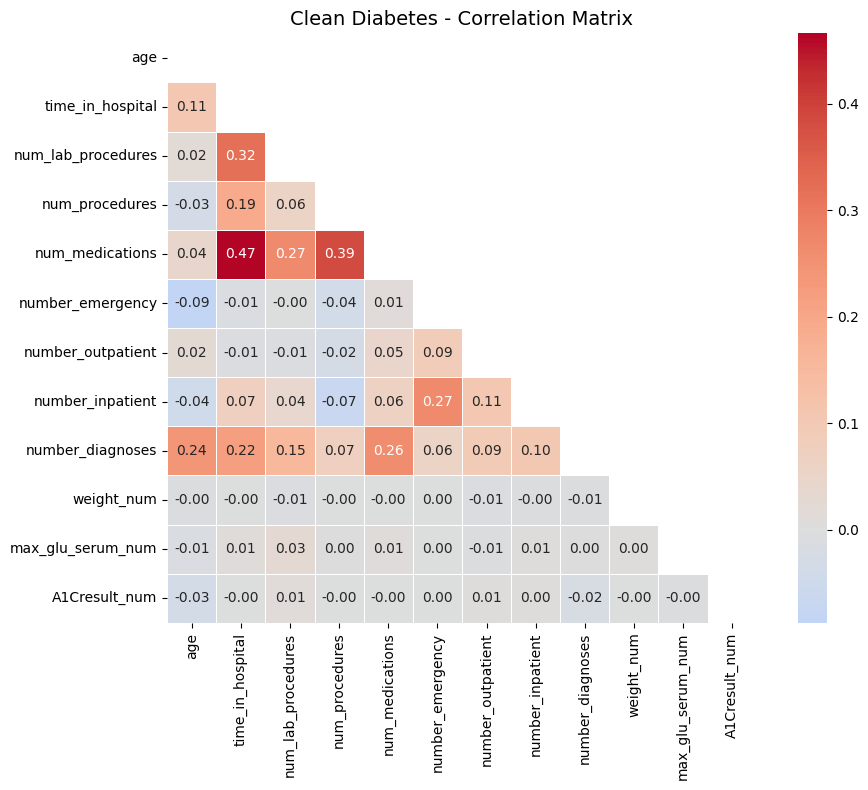

In [404]:
plot_corr_heatmap(cleandiabetes, numerical, "Clean Diabetes - Correlation Matrix")


## Breaking the data up into Train & Test

In [405]:
#@title Setting Up Data for Modeling 
#Uses the cleandiabetes dataset for modeling.
DataTesting = cleandiabetes.copy() #change it to sub2 or Sub3 to test each dataset

In [406]:
# Step 1: Split cleandiabetes into Train (70%) and Temp (30%)
train_df, temp_df = train_test_split(
    DataTesting,
    test_size=0.30,        # 30% goes to temp (valid + test)
    random_state=42,       # ensures reproducibility
    shuffle=True           # shuffles before splitting
)


# Step 2: Split Temp into Validation (15%) and Test (15%)
valid_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,        # half of temp = 15% of total
    random_state=42,
    shuffle=True
)

# Step 3: Reset indexes for cleanliness
train_df = train_df.reset_index(drop=True)
valid_df = valid_df.reset_index(drop=True)
test_df  = test_df.reset_index(drop=True)


# Step 4: Just Making Sure Check
print("Train size:", len(train_df))
print("Validation size:", len(valid_df))
print("Test size:", len(test_df))
print("Total:", len(train_df) + len(valid_df) + len(test_df))


Train size: 71236
Validation size: 15265
Test size: 15265
Total: 101766


In [407]:
DataTesting.lessthan30.value_counts()

lessthan30
0    90409
1    11357
Name: count, dtype: int64

In [408]:
train_df.lessthan30.value_counts()

lessthan30
0    63304
1     7932
Name: count, dtype: int64

In [409]:
valid_df.lessthan30.value_counts()

lessthan30
0    13500
1     1765
Name: count, dtype: int64

In [410]:
test_df.lessthan30.value_counts()

lessthan30
0    13605
1     1660
Name: count, dtype: int64

## Ways to Fix/Treat the Imbalance in the Data
Imbalance in the data means that one of the classes in the data is too less as compared to the others. Typically, it is better to balance the data in some way to give the positives more weight. There are 3 strategies that are typically utilized:

#### 1. RANDOM OVERSAMPLING: 
This technique involves randomly duplicating examples from the minority class in the training dataset. 
This can help balance the class distribution but may lead to overfitting since it replicates existing data points.

In [411]:
def balance_random_oversample(df, target='readmit_less_30', random_state=42):
    df_pos = df[df[target] == 1]
    df_neg = df[df[target] == 0]

    df_pos_over = resample(
        df_pos,
        replace=True,
        n_samples=len(df_neg),
        random_state=random_state
    )

    df_bal = (
        pd.concat([df_neg, df_pos_over])
        .sample(frac=1, random_state=random_state)
        .reset_index(drop=True)
    )

    return df_bal

#### 2. SMOTE 
(Synthetic Minority Over-sampling Technique): SMOTE generates synthetic examples of the minority class by interpolating between existing minority class examples. 
This can help create a more balanced dataset without simply duplicating existing data points, which may reduce the risk of overfitting compared to random oversampling.

In [412]:
def balance_smote(df, target='readmit_less_30', random_state=42):
    X = df.drop(columns=[target])
    y = df[target]

    sm = SMOTE(random_state=random_state)
    X_res, y_res = sm.fit_resample(X, y)

    df_bal = pd.concat(
        [pd.DataFrame(X_res, columns=X.columns),
         pd.Series(y_res, name=target)],
        axis=1
    )

    return df_bal

#### 3. RANDOM UNDERSAMPLING
Random Undersampling reduces the size of the majority class by randomly removing samples until it matches the minority class count. This creates a balanced dataset without generating synthetic data.

In [413]:
def balance_random_undersample(df, target='readmit_less_30', random_state=42):
    df_pos = df[df[target] == 1]
    df_neg = df[df[target] == 0]

    df_neg_under = df_neg.sample(
        n=len(df_pos),
        random_state=random_state
    )

    df_bal = (
        pd.concat([df_pos, df_neg_under])
        .sample(frac=1, random_state=random_state)
        .reset_index(drop=True)
    )

    return df_bal

#### 4. SMOTEENN


In [414]:
from imblearn.combine import SMOTEENN
from imblearn.over_sampling import SMOTE

def apply_smoteenn(X, y, k_neighbors=5, random_state=42):
    """
    Apply SMOTEENN hybrid resampling:
    - SMOTE oversamples the minority class
    - ENN removes noisy majority samples

    Returns:
        X_resampled, y_resampled
    """
    smote = SMOTE(k_neighbors=k_neighbors, random_state=random_state)
    smote_enn = SMOTEENN(smote=smote, random_state=random_state)

    X_resampled, y_resampled = smote_enn.fit_resample(X, y)
    return X_resampled, y_resampled

#### 5. SMOTETOMEK

In [415]:
from imblearn.combine import SMOTETomek

def apply_smotetomek(X, y, k_neighbors=5, random_state=42):
    """
    Apply SMOTETomek hybrid resampling:
    - SMOTE oversamples the minority class
    - Tomek Links remove borderline/noisy majority samples

    Returns:
        X_resampled, y_resampled
    """
    smote = SMOTE(k_neighbors=k_neighbors, random_state=random_state)
    smote_tomek = SMOTETomek(smote=smote, random_state=random_state)

    X_resampled, y_resampled = smote_tomek.fit_resample(X, y)
    return X_resampled, y_resampled


#### Prevalence Caculation Function

In [416]:
def calc_prevalence(y_actual):
    """
    Calculate the prevalence (ratio of positive class = 1)
    in a binary target array or Series.
    """
    y_actual = pd.Series(y_actual)
    return y_actual.mean()

<h2 style="color:#e63946;">CHANGE THE IMBALANCE TECHNIQUE HERE</h2>
“Remove the # to activate a specific technique."


In [417]:
# 1. Split train_df into X and y
X_train = train_df.drop(columns=["lessthan30"])
y_train = train_df["lessthan30"]

# 2. Apply SMOTEENN
X_bal, y_bal = apply_smoteenn(X_train, y_train)

# 3. Combine back into a single DataFrame (optional)
train_balanced = X_bal.copy()
train_balanced["lessthan30"] = y_bal

# 4. Check prevalence
print(
    "Train balanced prevalence (n = %d): %.3f" %
    (len(train_balanced), calc_prevalence(train_balanced['lessthan30']))
)


Train balanced prevalence (n = 95386): 0.641


In [418]:
train_balanced.lessthan30.value_counts()

lessthan30
1    61173
0    34213
Name: count, dtype: int64

In [419]:
X_train = train_balanced.drop('lessthan30',axis=1)

y_train = train_balanced['lessthan30']

X_valid = valid_df.drop('lessthan30',axis=1)

y_valid = valid_df['lessthan30']

X_test = test_df.drop('lessthan30',axis=1)

y_test = test_df['lessthan30']

<h2 style="color:#e63946;">CHANGE THE SETS HERE FOR SCALER</h2>

In [420]:
scale_cols = numerical
# -----------------------------------------
# 1. Fit the scaler on TRAINING data only
# -----------------------------------------
scaler = StandardScaler()
X_train[scale_cols] = scaler.fit_transform(X_train[scale_cols])

# -----------------------------------------
# 2. Transform VALIDATION and TEST sets
# -----------------------------------------
X_valid[scale_cols] = scaler.transform(X_valid[scale_cols])
X_test[scale_cols]  = scaler.transform(X_test[scale_cols])


In [421]:
X_train.head()

,age,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,number_diagnoses,diabetesMed,...,diag3_unknown,Race_Caucasian,Race_AfricanAmerican,Race_Unknown,Race_Other,Race_Asian,Race_Hispanic,weight_num,max_glu_serum_num,A1Cresult_num
0,-0.081264,-0.105537,-0.227109,-0.730273,-0.662089,-0.275277,-0.213574,-0.546876,-1.354635,0,...,0,1,0,0,0,0,0,-1.520738,-0.364265,-0.028440
1,1.211326,-1.197687,-0.331913,0.621440,-1.191039,-0.275277,-0.213574,-0.546876,-1.354635,0,...,0,1,0,0,0,0,0,-0.855338,1.101047,-0.028440
2,-0.081264,2.806864,0.401714,-0.730273,-0.529851,-0.275277,-0.213574,-0.546876,-0.218210,1,...,0,1,0,0,0,0,0,0.459988,-1.502606,-1.246531
3,-0.727559,-0.105537,-0.489119,-0.730273,0.263574,-0.275277,-0.213574,-0.546876,0.918215,0,...,0,1,0,0,0,0,0,-0.236361,1.161597,-0.284880
4,0.565031,-0.469587,-1.275147,-0.730273,0.924762,-0.275277,2.016890,0.894924,0.350002,1,...,0,1,0,0,0,0,0,1.125388,0.301786,0.484441


In [422]:
X_train.head().T

,0,1,2,3,4
age,-0.081264,1.211326,-0.081264,-0.727559,0.565031
time_in_hospital,-0.105537,-1.197687,2.806864,-0.105537,-0.469587
num_lab_procedures,-0.227109,-0.331913,0.401714,-0.489119,-1.275147
num_procedures,-0.730273,0.621440,-0.730273,-0.730273,-0.730273
num_medications,-0.662089,-1.191039,-0.529851,0.263574,0.924762
...,...,...,...,...,...
Race_Asian,0.000000,0.000000,0.000000,0.000000,0.000000
Race_Hispanic,0.000000,0.000000,0.000000,0.000000,0.000000
weight_num,-1.520738,-0.855338,0.459988,-0.236361,1.125388
max_glu_serum_num,-0.364265,1.101047,-1.502606,1.161597,0.301786


## Creating and Understanding Models

In [423]:
def calc_specificity(y_actual, y_pred, thresh):
    # calculates specificity
    return sum((y_pred < thresh) & (y_actual == 0)) /sum(y_actual ==0)

def print_report(y_actual, y_pred, thresh = 0.5):
    
    '''
    This function calculates all the metrics to asses the machine learning models.
    
    Params:
    1. y_actual: The actual values for the target variable.
    2. y_pred: The predicted values for the target variable.
    3. thresh: The threshold for the probability to be considered as a positive class. Default value 0.5
    
    Return:
    1. AUC - ROC Curve
    2. Accuracy
    3. Recall
    4. Precision
    5. Specificity
    '''
    
    auc = roc_auc_score(y_actual, y_pred)
    accuracy = accuracy_score(y_actual, (y_pred > thresh))
    recall = recall_score(y_actual, (y_pred > thresh))
    precision = precision_score(y_actual, (y_pred > thresh))
    specificity = calc_specificity(y_actual, y_pred, thresh)
    print('AUC:%.3f'%auc)
    print('accuracy:%.3f'%accuracy)
    print('recall:%.3f'%recall)
    print('precision:%.3f'%precision)
    print('specificity:%.3f'%specificity)
    print('prevalence:%.3f'%calc_prevalence(y_actual))
    print(' ')
    return auc, accuracy, recall, precision, specificity

### Linear Regression

In [424]:
# disable truncation so NumPy prints the entire array
np.set_printoptions(threshold=np.inf)

lnr = LinearRegression()
lnr.fit(X_train, y_train)

y_valid_preds = lnr.predict(X_valid)

In [425]:
print(y_valid_preds)

[ 2.74132304e-01  2.70236594e-01  3.08236016e-01  1.29602784e-01
  2.23196064e-01  1.67235454e-01  2.70765954e-01  1.64181884e-01
  4.43537258e-01  3.51527682e-01  2.18860243e-01  2.84586748e-01
  2.61476566e-01  1.97962524e-01  3.04092663e-01  1.81927894e-01
  3.22257511e-01  2.51023624e-01  1.81661442e-01  2.54778482e-01
  8.45617869e-02  3.43444977e-01  2.96739853e-01  2.69100949e-01
  2.49466785e-01  2.27266639e-01  2.67368504e-01  4.19420820e-01
  1.56431601e-01  2.34269140e-01  1.92025014e-01  2.05442326e-01
  3.01044662e-02  7.85006476e-02  4.09282107e-01  3.89668580e-01
  1.34797010e-01  3.11668779e-01  3.16821311e-01  3.26169491e-01
  2.21530431e-01  2.84094295e-01  3.08656939e-01  1.57992764e-01
  1.77318795e-01  2.74661980e-01  1.74058958e-01  3.02759308e-01
  3.48524911e-01  2.94470079e-01  3.37768312e-01  4.10227781e-01
  1.34310394e-01  1.54499787e-01  1.06906910e-01  1.58708721e-01
  1.88367643e-01  2.94107554e-01  2.89971307e-01  1.07703843e-01
  2.37364703e-01  3.69432

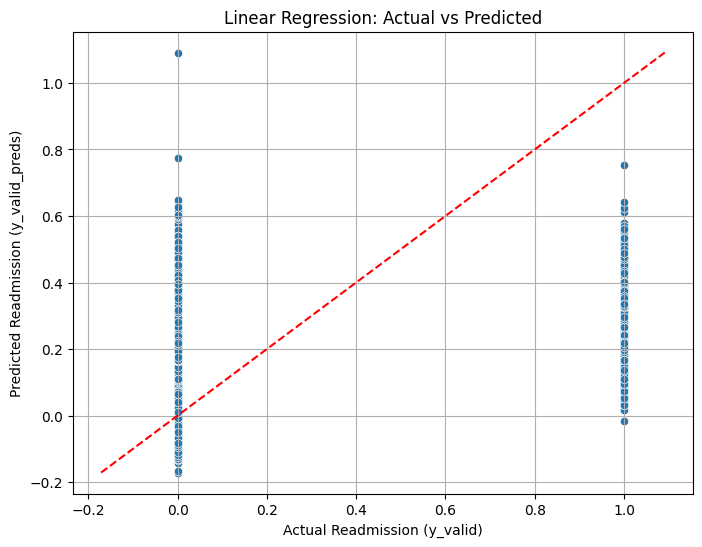

In [426]:
# Create a scatter plot of Actual vs Predicted
plt.figure(figsize=(8,6))
sns.scatterplot(x=y_valid, y=y_valid_preds)

# Add a 45-degree reference line
min_val = min(y_valid.min(), y_valid_preds.min())
max_val = max(y_valid.max(), y_valid_preds.max())
plt.plot([min_val, max_val], [min_val, max_val], color='red', linestyle='--')

plt.xlabel("Actual Readmission (y_valid)")
plt.ylabel("Predicted Readmission (y_valid_preds)")
plt.title("Linear Regression: Actual vs Predicted")
plt.grid(True)
plt.show()


### Logistic Regression

In [427]:
lr=LogisticRegression(random_state = 42, solver = 'newton-cg', max_iter = 200)
lr.fit(X_train, y_train)

y_valid_preds = lr.predict_proba(X_valid)[:,1]

print('Metrics for Validation data:')

lr_valid_auc, lr_valid_accuracy, lr_valid_recall, \
    lr_valid_precision, lr_valid_specificity = print_report(y_valid,y_valid_preds, 0.5)

Metrics for Validation data:
AUC:0.665
accuracy:0.879
recall:0.057
precision:0.357
specificity:0.987
prevalence:0.116
 


### KNN Model

In [428]:
knn = KNeighborsClassifier(n_neighbors = 100)
knn.fit(X_train, y_train)

knn_preds = knn.predict_proba(X_valid)[:,1]

lr_valid_auc, lr_valid_accuracy, lr_valid_recall, \
    lr_valid_precision, lr_valid_specificity = print_report(y_valid,knn_preds, 0.5)

AUC:0.589
accuracy:0.200
recall:0.950
precision:0.121
specificity:0.095
prevalence:0.116
 


### Stochastic Gradient Descent Model

In [429]:
sgdc = SGDClassifier(loss='log_loss', alpha=0.1, random_state=42)
sgdc.fit(X_train, y_train)

sgd_preds = sgdc.predict_proba(X_valid)[:, 1]

print('Stochastic Gradient Descent')
print('Validation:')
sgdc_valid_auc, sgdc_valid_accuracy, sgdc_valid_recall, \
sgdc_valid_precision, sgdc_valid_specificity = print_report(y_valid, sgd_preds, 0.5)

Stochastic Gradient Descent
Validation:
AUC:0.599
accuracy:0.441
recall:0.734
precision:0.138
specificity:0.403
prevalence:0.116
 


### Decision Tree

In [430]:
dc_clf = DecisionTreeClassifier(random_state=42, max_depth = 10)
dc_clf.fit(X_train, y_train)

dc_preds_proba = dc_clf.predict_proba(X_valid)[:,1]
dc_preds = dc_clf.predict(X_valid)

lr_valid_auc, lr_valid_accuracy, lr_valid_recall, \
    lr_valid_precision, lr_valid_specificity = print_report(y_valid,dc_preds_proba, 0.5)

AUC:0.604
accuracy:0.766
recall:0.220
precision:0.150
specificity:0.835
prevalence:0.116
 


### Random Forest

In [431]:
rf_clf = RandomForestClassifier(random_state=111, max_depth = 3)

rf_clf.fit(X_train, y_train)

rf_preds = rf_clf.predict(X_valid)
rf_preds_proba = rf_clf.predict_proba(X_valid)[:, 1]

lr_valid_auc, lr_valid_accuracy, lr_valid_recall, \
    lr_valid_precision, lr_valid_specificity = print_report(y_valid,rf_preds_proba, 0.5)

AUC:0.565
accuracy:0.215
recall:0.927
precision:0.121
specificity:0.122
prevalence:0.116
 


### Linear SVC

In [432]:
lsvc_clf = LinearSVC(random_state=111)
lsvc_clf.fit(X_train, y_train)

lsvc_preds = lsvc_clf.decision_function(X_valid)

lr_valid_auc, lr_valid_accuracy, lr_valid_recall, \
    lr_valid_precision, lr_valid_specificity = print_report(y_valid,lsvc_preds, 0.5)

AUC:0.669
accuracy:0.884
recall:0.007
precision:0.500
specificity:0.999
prevalence:0.116
 


### Gradient Boosting Model

In [433]:
gb_clf = GradientBoostingClassifier(n_estimators = 100, criterion='friedman_mse', learning_rate = 1.0, max_depth = 3,\
                                    random_state = 111)

gb_clf.fit(X_train, y_train)
gb_preds = gb_clf.predict(X_valid)
gb_preds_proba = gb_clf.predict_proba(X_valid)[:, 1]

lr_valid_auc, lr_valid_accuracy, lr_valid_recall, \
    lr_valid_precision, lr_valid_specificity = print_report(y_valid,gb_preds_proba, 0.5)

AUC:0.644
accuracy:0.865
recall:0.118
precision:0.291
specificity:0.962
prevalence:0.116
 


### XGB Model

In [434]:
xgb_clf = xgb.XGBClassifier(max_depth=3, learning_rate = 1.0, use_label_encoder = False,\
                            eval_metric = 'logloss')
xgb_clf.fit(X_train, y_train)

xgb_preds = xgb_clf.predict(X_valid)
xgb_preds_proba = xgb_clf.predict_proba(X_valid)[:, 1]

lr_valid_auc, lr_valid_accuracy, lr_valid_recall, \
    lr_valid_precision, lr_valid_specificity = print_report(y_valid,xgb_preds_proba, 0.5)

AUC:0.632
accuracy:0.857
recall:0.129
precision:0.259
specificity:0.952
prevalence:0.116
 


### Catboost Model

In [435]:
catb=CatBoostClassifier(iterations=200, depth=3, learning_rate=1.0, random_state = 111)
catb.fit(X_train, y_train)
catb_preds = catb.predict_proba(X_valid)[:, 1]

lr_valid_auc, lr_valid_accuracy, lr_valid_recall, \
    lr_valid_precision, lr_valid_specificity = print_report(y_valid,catb_preds, 0.5)

0:	learn: 0.5438861	total: 162ms	remaining: 32.2s
1:	learn: 0.4868244	total: 168ms	remaining: 16.6s
2:	learn: 0.4485781	total: 174ms	remaining: 11.4s
3:	learn: 0.4213399	total: 178ms	remaining: 8.74s
4:	learn: 0.3977042	total: 186ms	remaining: 7.24s
5:	learn: 0.3774543	total: 190ms	remaining: 6.16s
6:	learn: 0.3579727	total: 196ms	remaining: 5.39s
7:	learn: 0.3337366	total: 201ms	remaining: 4.83s
8:	learn: 0.3183970	total: 206ms	remaining: 4.37s
9:	learn: 0.3059812	total: 212ms	remaining: 4.03s
10:	learn: 0.2906936	total: 218ms	remaining: 3.75s
11:	learn: 0.2834775	total: 223ms	remaining: 3.5s
12:	learn: 0.2770763	total: 229ms	remaining: 3.29s
13:	learn: 0.2710315	total: 235ms	remaining: 3.12s
14:	learn: 0.2650934	total: 240ms	remaining: 2.96s
15:	learn: 0.2605340	total: 246ms	remaining: 2.83s
16:	learn: 0.2566004	total: 252ms	remaining: 2.71s
17:	learn: 0.2497667	total: 256ms	remaining: 2.59s
18:	learn: 0.2455771	total: 261ms	remaining: 2.49s
19:	learn: 0.2421493	total: 266ms	remainin

## Hyper Parameter Tuning

### Decision Tree

In [436]:
# Decision Tree - Hyperparameter Tuning
recall_scoring = make_scorer(recall_score)

dc_grid = {'max_features':['auto','sqrt'], # maximum number of features to use at each split
           'max_depth':range(1,11,1), # maximum depth of the tree
           'min_samples_split':range(2,10,2), # minimum number of samples to split a node
           'min_samples_leaf': range(1, 11, 2), ###  -->> Added a critical param
           'criterion':['gini','entropy']} # criterion for evaluating a split

dc_random = RandomizedSearchCV(estimator = dc_clf, param_distributions = dc_grid,
                               n_iter = 20,
                               cv = 10,              ### -->> chnaged cv from 2 to 5
                               scoring ='recall',   ### -->> changed fromscoring=recall_scoring,
                               verbose = 1, random_state = 111)

dc_random.fit(X_train, y_train)

dc_random.best_params_

dc_hp_preds = dc_random.best_estimator_.predict(X_valid)
dc_hp_preds_proba = dc_random.best_estimator_.predict_proba(X_valid)[:,1]
roc_auc_score(y_valid, dc_hp_preds_proba)

# added later
print("Best params:", dc_random.best_params_)
print("Best CV recall:", dc_random.best_score_)
print("Validation recall:", recall_score(y_valid, dc_random.best_estimator_.predict(X_valid)))

"""
Fitting 5 folds for each of 20 candidates, totalling 100 fits
Best params: {'min_samples_split': 6, 'min_samples_leaf': 1, 'max_features': 'sqrt', 'max_depth': 1, 'criterion': 'entropy'}
Best CV recall: 0.8327703475995127
Validation recall: 0.996244131455399

add all metrics from above
"""

Fitting 10 folds for each of 20 candidates, totalling 200 fits
Best params: {'min_samples_split': 6, 'min_samples_leaf': 1, 'max_features': 'sqrt', 'max_depth': 1, 'criterion': 'entropy'}
Best CV recall: 0.9459557961581992
Validation recall: 0.8356940509915014


"\nFitting 5 folds for each of 20 candidates, totalling 100 fits\nBest params: {'min_samples_split': 6, 'min_samples_leaf': 1, 'max_features': 'sqrt', 'max_depth': 1, 'criterion': 'entropy'}\nBest CV recall: 0.8327703475995127\nValidation recall: 0.996244131455399\n\nadd all metrics from above\n"

In [437]:

recall_score(y_valid, dc_hp_preds)

0.8356940509915014

### Random Forest

In [438]:
# Random Forest - Hyperparameter Tuning
recall_scoring = make_scorer(recall_score)

rf_grid = {'n_estimators':range(200,1000,200), # number of trees
           'max_features':['auto','sqrt'], # maximum number of features to use at each split
           'max_depth':range(1,11,1), # maximum depth of the tree
           'min_samples_split':range(2,10,2), # minimum number of samples to split a node
           'criterion':['gini','entropy']} # criterion for evaluating a split

rf_random = RandomizedSearchCV(estimator = rf_clf, param_distributions = rf_grid,
                               n_iter = 20, cv = 2, scoring=recall_scoring,
                               verbose = 1, random_state = 111)

rf_random.fit(X_train, y_train)

rf_random.best_params_

rf_hp_preds = rf_random.best_estimator_.predict(X_valid)
rf_hp_preds_proba = rf_random.best_estimator_.predict_proba(X_valid)[:,1]
roc_auc_score(y_valid, rf_hp_preds_proba)

Fitting 2 folds for each of 20 candidates, totalling 40 fits


0.5607022767810304

In [439]:

recall_score(y_valid, dc_hp_preds)

0.8356940509915014

### XGBoost

In [440]:
#xgboost - Hyperparameter Tuning
recall_scoring = make_scorer(recall_score)

xgb_grid = params = {
        'min_child_weight': [1, 5, 8, 10],
        'gamma': [0.5, 1, 1.5, 2, 5],
        'subsample': [0.6, 0.8, 1.0],
        'colsample_bytree': [0.6, 0.8, 0.9, 1.0],
        'max_depth': [3, 4, 5]
        } # criterion for evaluating a split

xgb_random = GridSearchCV(estimator = xgb_clf, param_grid = xgb_grid,
                               cv = 2, scoring = recall_scoring,
                               verbose = 1)

xgb_random.fit(X_train, y_train)

xgb_random.best_params_

xgb_hp_preds = xgb_random.best_estimator_.predict(X_valid)
xgb_hp_preds_proba = xgb_random.best_estimator_.predict_proba(X_valid)[:,1]
roc_auc_score(y_valid, xgb_hp_preds_proba)

Fitting 2 folds for each of 720 candidates, totalling 1440 fits


0.6203670129052565

In [441]:

recall_score(y_valid, dc_hp_preds)

0.8356940509915014

#### 4. SAVING PKL MODEL

In [443]:
import joblib
import numpy as np
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score, recall_score, precision_score, accuracy_score, confusion_matrix

# ============================================================
# TARGET
# ============================================================
target = "lessthan30"

print("\n" + "="*70)
print(f"     RANDOM FOREST — FINAL MODEL ({target.upper()}) ")
print("="*70)

prev = y_valid.mean()

# ============================================================
# TRAIN RANDOM FOREST
# ============================================================
rf = RandomForestClassifier(
    n_estimators=100,
    max_depth=6,
    min_samples_split=2,
    random_state=111,
    n_jobs=-1
)

rf.fit(X_train, y_train)

# ============================================================
# PREDICT PROBABILITIES
# ============================================================
preds_proba = rf.predict_proba(X_valid)[:, 1]

# ============================================================
# METRICS
# ============================================================
auc = roc_auc_score(y_valid, preds_proba)

preds = (preds_proba >= 0.5).astype(int)

acc = accuracy_score(y_valid, preds)
rec = recall_score(y_valid, preds)
prec = precision_score(y_valid, preds)

tn, fp, fn, tp = confusion_matrix(y_valid, preds).ravel()
spec = tn / (tn + fp)

# ============================================================
# PRINT RESULTS
# ============================================================
print("\nValidation Metrics (Random Forest):")
print("-"*50)
print(f"AUC:          {auc:.4f}")
print(f"Accuracy:     {acc:.4f}")
print(f"Recall:       {rec:.4f}")
print(f"Precision:    {prec:.4f}")
print(f"Specificity:  {spec:.4f}")
print(f"Prevalence:   {prev:.4f}")
print("="*70)

# ============================================================
# SAVE MODEL
# ============================================================
filename = f"{target}_RandomForest_Tuned.Smoteenn.Imputations.pkl"
joblib.dump(rf_random.best_estimator_, filename)

print(f"Saved Tuned Random Forest model as '{filename}'")
print("="*70 + "\n")

final_models = {target: rf_random.best_estimator_}



     RANDOM FOREST — FINAL MODEL (LESSTHAN30) 

Validation Metrics (Random Forest):
--------------------------------------------------
AUC:          0.5841
Accuracy:     0.5764
Recall:       0.5258
Precision:    0.1415
Specificity:  0.5830
Prevalence:   0.1156
Saved Tuned Random Forest model as 'lessthan30_RandomForest_Tuned.Smoteenn.Imputations.pkl'



In [444]:
from sklearn.metrics import accuracy_score, recall_score, precision_score, roc_auc_score

def binarize(preds, threshold=0.5):
    return (preds >= threshold).astype(int)

results = []

# Logistic Regression
results.append([
    "Logistic Regression",
    roc_auc_score(y_valid, y_valid_preds),
    accuracy_score(y_valid, binarize(y_valid_preds)),
    recall_score(y_valid, binarize(y_valid_preds)),
    precision_score(y_valid, binarize(y_valid_preds)),
    recall_score(y_valid, binarize(y_valid_preds), pos_label=0)
])

# KNN
results.append([
    "KNN",
    roc_auc_score(y_valid, knn_preds),
    accuracy_score(y_valid, binarize(knn_preds)),
    recall_score(y_valid, binarize(knn_preds)),
    precision_score(y_valid, binarize(knn_preds)),
    recall_score(y_valid, binarize(knn_preds), pos_label=0)
])

# SGDClassifier
results.append([
    "SGDClassifier",
    roc_auc_score(y_valid, sgd_preds),
    accuracy_score(y_valid, binarize(sgd_preds)),
    recall_score(y_valid, binarize(sgd_preds)),
    precision_score(y_valid, binarize(sgd_preds)),
    recall_score(y_valid, binarize(sgd_preds), pos_label=0)
])

# Decision Tree
results.append([
    "Decision Tree",
    roc_auc_score(y_valid, dc_preds_proba),
    accuracy_score(y_valid, dc_preds),
    recall_score(y_valid, dc_preds),
    precision_score(y_valid, dc_preds),
    recall_score(y_valid, dc_preds, pos_label=0)
])

# Random Forest
results.append([
    "Random Forest",
    roc_auc_score(y_valid, rf_preds_proba),
    accuracy_score(y_valid, rf_preds),
    recall_score(y_valid, rf_preds),
    precision_score(y_valid, rf_preds),
    recall_score(y_valid, rf_preds, pos_label=0)
])

# Linear SVC
results.append([
    "Linear SVC",
    roc_auc_score(y_valid, lsvc_preds),
    accuracy_score(y_valid, binarize(lsvc_preds, threshold=0)),
    recall_score(y_valid, binarize(lsvc_preds, threshold=0)),
    precision_score(y_valid, binarize(lsvc_preds, threshold=0)),
    recall_score(y_valid, binarize(lsvc_preds, threshold=0), pos_label=0)
])

# Gradient Boosting
results.append([
    "Gradient Boosting",
    roc_auc_score(y_valid, gb_preds_proba),
    accuracy_score(y_valid, gb_preds),
    recall_score(y_valid, gb_preds),
    precision_score(y_valid, gb_preds),
    recall_score(y_valid, gb_preds, pos_label=0)
])

# XGBoost
results.append([
    "XGBoost",
    roc_auc_score(y_valid, xgb_preds_proba),
    accuracy_score(y_valid, xgb_preds),
    recall_score(y_valid, xgb_preds),
    precision_score(y_valid, xgb_preds),
    recall_score(y_valid, xgb_preds, pos_label=0)
])

# CatBoost
results.append([
    "CatBoost",
    roc_auc_score(y_valid, catb_preds),
    accuracy_score(y_valid, binarize(catb_preds)),
    recall_score(y_valid, binarize(catb_preds)),
    precision_score(y_valid, binarize(catb_preds)),
    recall_score(y_valid, binarize(catb_preds), pos_label=0)
])

# Decision Tree (HP Tuned)
results.append([
    "Decision Tree (HP Tuned)",
    roc_auc_score(y_valid, dc_hp_preds_proba),
    accuracy_score(y_valid, dc_hp_preds),
    recall_score(y_valid, dc_hp_preds),
    precision_score(y_valid, dc_hp_preds),
    recall_score(y_valid, dc_hp_preds, pos_label=0)
])

# Random Forest (HP Tuned)
results.append([
    "Random Forest (HP Tuned)",
    roc_auc_score(y_valid, rf_hp_preds_proba),
    accuracy_score(y_valid, rf_hp_preds),
    recall_score(y_valid, rf_hp_preds),
    precision_score(y_valid, rf_hp_preds),
    recall_score(y_valid, rf_hp_preds, pos_label=0)
])

# XGBoost (HP Tuned)
results.append([
    "XGBoost (HP Tuned)",
    roc_auc_score(y_valid, xgb_hp_preds_proba),
    accuracy_score(y_valid, xgb_hp_preds),
    recall_score(y_valid, xgb_hp_preds),
    precision_score(y_valid, xgb_hp_preds),
    recall_score(y_valid, xgb_hp_preds, pos_label=0)
])

results_df = pd.DataFrame(results, columns=["Model", "AUC", "Accuracy", "Recall", "Precision", "Specificity"])
results_df


,Model,AUC,Accuracy,Recall,Precision,Specificity
0,Logistic Regression,0.665023,0.879135,0.056657,0.357143,0.986667
1,KNN,0.589063,0.194432,0.954108,0.121151,0.095111
2,SGDClassifier,0.599326,0.441140,0.733711,0.138414,0.402889
3,Decision Tree,0.603814,0.766132,0.219830,0.150329,0.837556
4,Random Forest,0.564933,0.215198,0.926912,0.121302,0.122148
5,Linear SVC,0.668512,0.881166,0.045326,0.382775,0.990444
6,Gradient Boosting,0.643717,0.864658,0.118414,0.290682,0.962222
7,XGBoost,0.632245,0.856731,0.128612,0.259132,0.951926
8,CatBoost,0.652909,0.870947,0.120680,0.337559,0.969037
9,Decision Tree (HP Tuned),0.511403,0.262103,0.835694,0.118483,0.187111


SHAP Explainability Analysis

Using 100 samples for SHAP analysis

1. RANDOM FOREST (HP TUNED) - SHAP Explainability
----------------------------------------------------------------------


<Figure size 1000x600 with 0 Axes>

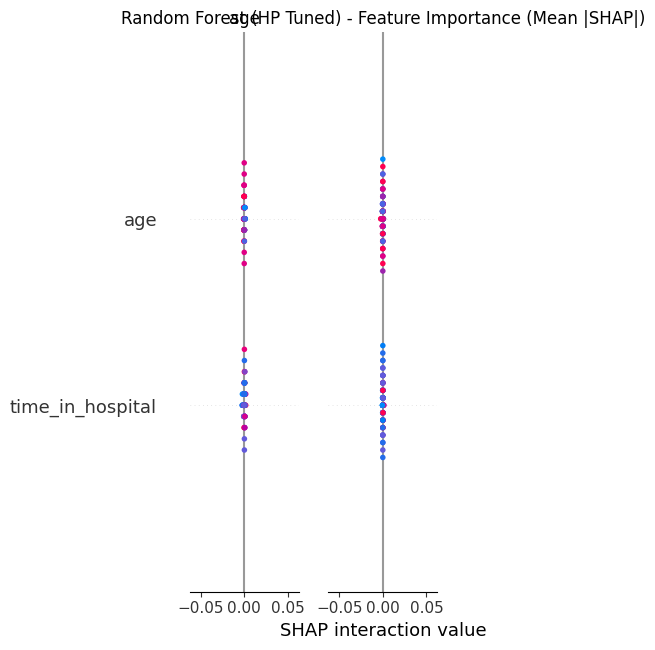

✓ Summary plot generated



<Figure size 1200x800 with 0 Axes>

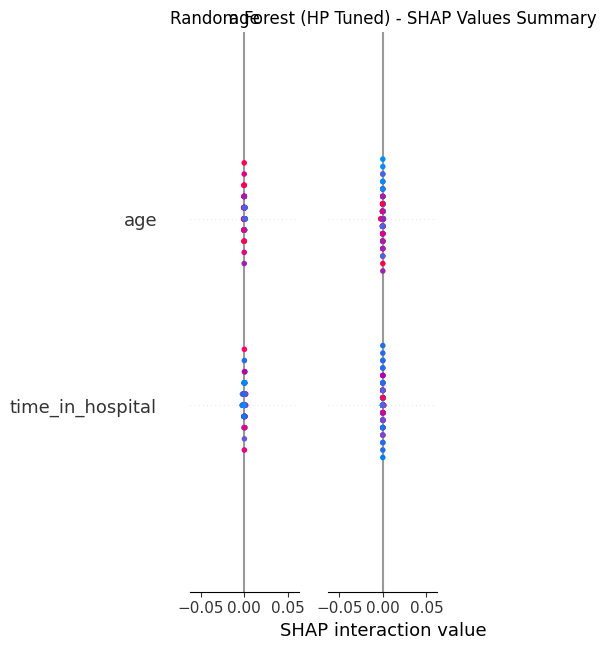

✓ Detailed summary plot generated

2. XGBOOST (HP TUNED) - SHAP Explainability
----------------------------------------------------------------------


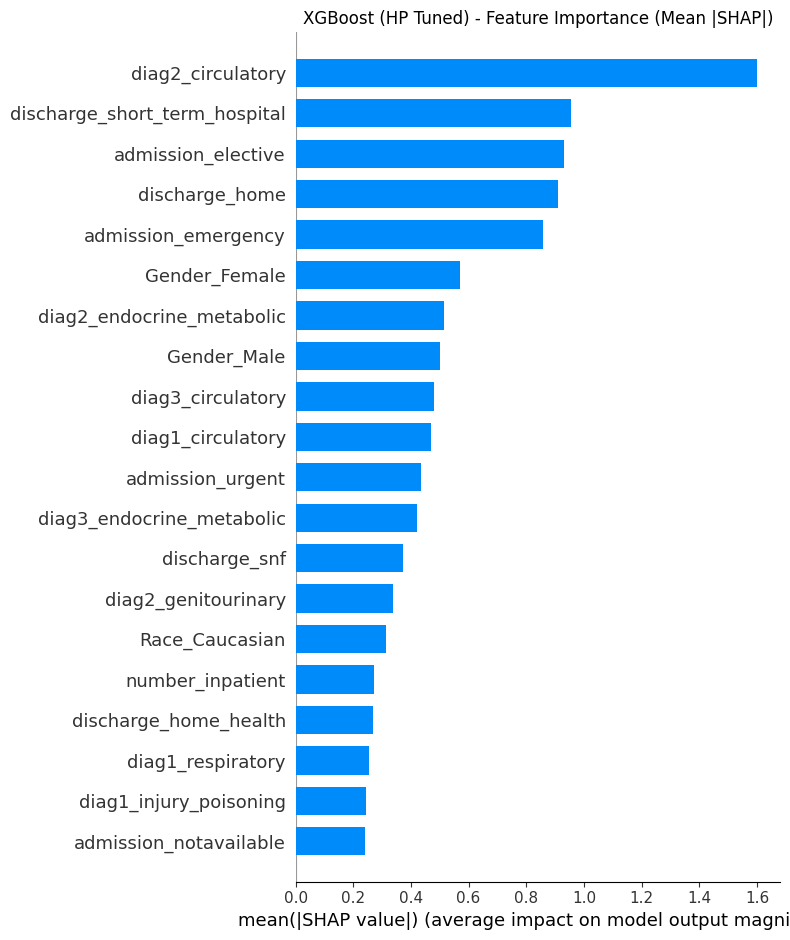

✓ Summary plot generated



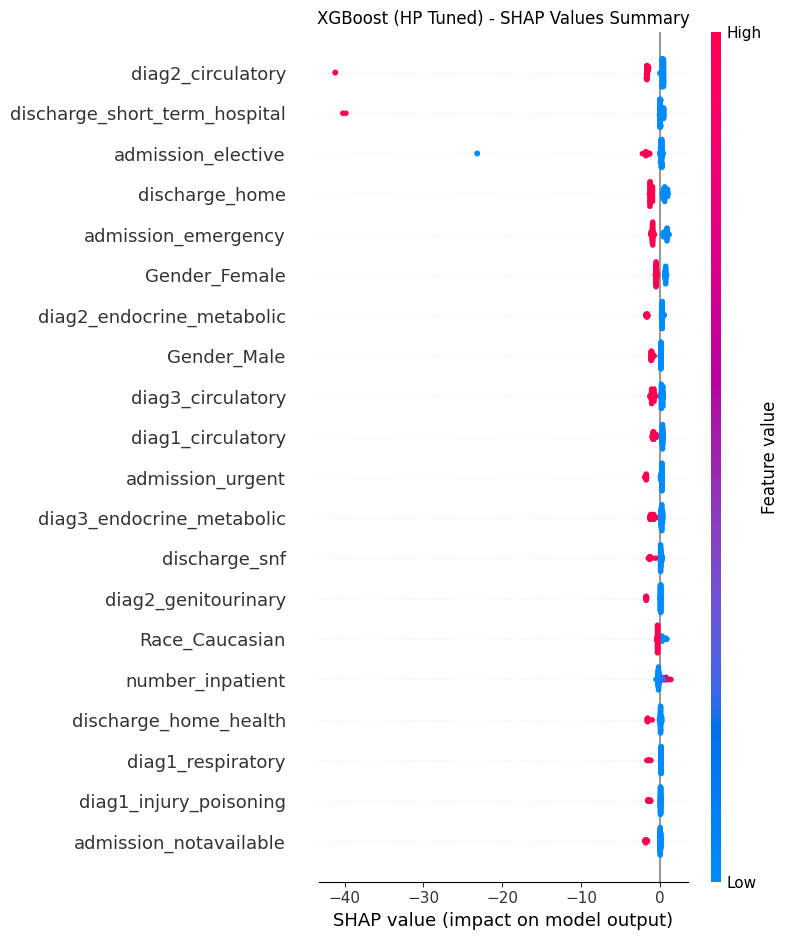

✓ Detailed summary plot generated

3. CATBOOST - SHAP Explainability
----------------------------------------------------------------------


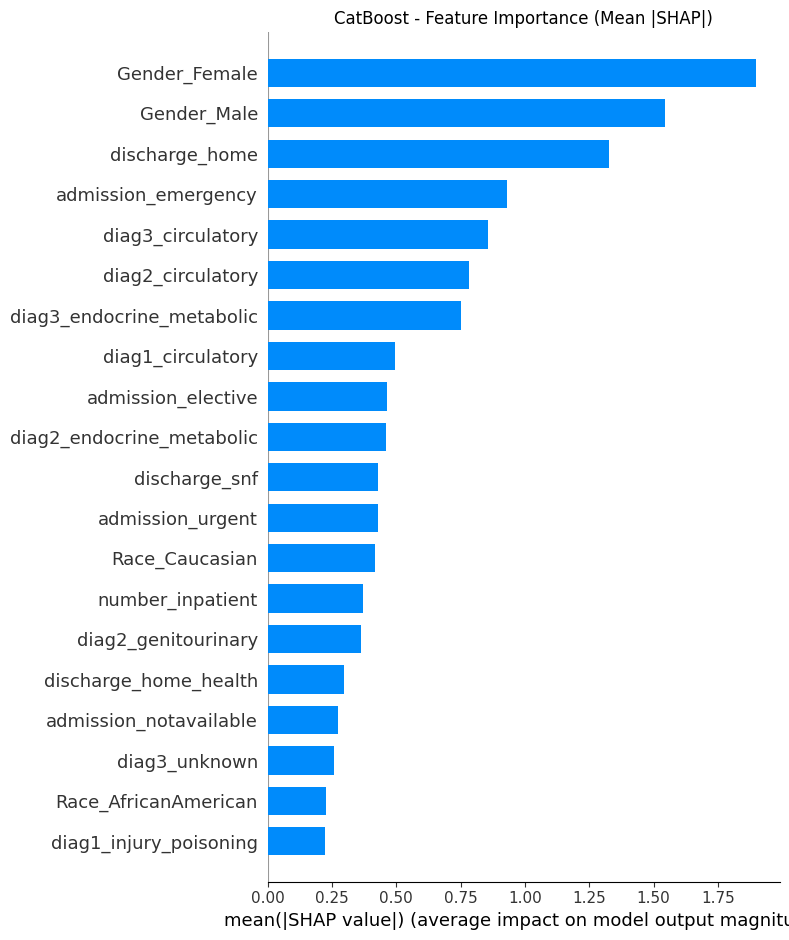

✓ Summary plot generated



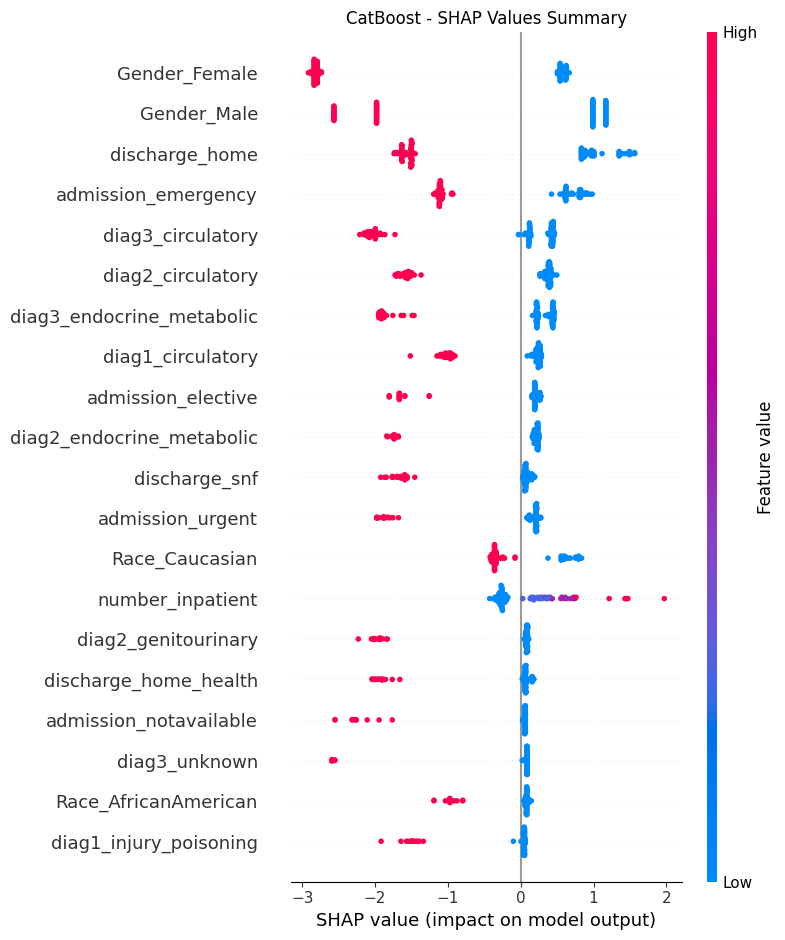

✓ Detailed summary plot generated

4. Individual Prediction Explanations (Force Plots)
----------------------------------------------------------------------
Error in force plot analysis: matplotlib = True is not yet supported for force plots with multiple samples!

5. Feature Dependence Analysis
----------------------------------------------------------------------
Error in dependence plot analysis: Multi-dimensional indexing (e.g. `obj[:, None]`) is no longer supported. Convert to a numpy array before indexing instead.

6. Feature Importance Comparison Across Models
----------------------------------------------------------------------
Error in feature importance comparison: Per-column arrays must each be 1-dimensional

7. SHAP Analysis Summary Statistics
----------------------------------------------------------------------
Random Forest - Mean |SHAP|: 0.0022
XGBoost - Mean |SHAP|: 0.1552
CatBoost - Mean |SHAP|: 0.1688

Interpretation Guide:
- Larger |SHAP| values indicate features 

<Figure size 1400x400 with 0 Axes>

In [447]:
import shap
import matplotlib.pyplot as plt
import numpy as np

print("=" * 70)
print("SHAP Explainability Analysis")
print("=" * 70 + "\n")

# Create a sample of data for faster SHAP computation
sample_size = min(100, len(X_valid))
X_sample = X_valid.iloc[:sample_size]
y_sample = y_valid.iloc[:sample_size]

print(f"Using {sample_size} samples for SHAP analysis\n")

# ============================================================================
# 1. RANDOM FOREST (HP TUNED) - SHAP Analysis
# ============================================================================
print("1. RANDOM FOREST (HP TUNED) - SHAP Explainability")
print("-" * 70)

try:
    # Create SHAP explainer for Random Forest
    explainer_rf = shap.TreeExplainer(rf_clf)
    shap_values_rf = explainer_rf.shap_values(X_sample)
    
    # For binary classification, take class 1 (positive class) explanations
    if isinstance(shap_values_rf, list):
        shap_values_rf = shap_values_rf[1]
    
    # Summary plot
    plt.figure(figsize=(10, 6))
    shap.summary_plot(shap_values_rf, X_sample, plot_type="bar", show=False)
    plt.title("Random Forest (HP Tuned) - Feature Importance (Mean |SHAP|)")
    plt.tight_layout()
    plt.show()
    
    print("✓ Summary plot generated\n")
    
    # Detailed summary plot (shows individual impact)
    plt.figure(figsize=(12, 8))
    shap.summary_plot(shap_values_rf, X_sample, show=False)
    plt.title("Random Forest (HP Tuned) - SHAP Values Summary")
    plt.tight_layout()
    plt.show()
    
    print("✓ Detailed summary plot generated\n")
    
except Exception as e:
    print(f"Error in Random Forest SHAP analysis: {e}\n")

# ============================================================================
# 2. XGBOOST (HP TUNED) - SHAP Analysis
# ============================================================================
print("2. XGBOOST (HP TUNED) - SHAP Explainability")
print("-" * 70)

try:
    # Create SHAP explainer for XGBoost
    explainer_xgb = shap.TreeExplainer(xgb_clf)
    shap_values_xgb = explainer_xgb.shap_values(X_sample)
    
    # XGBoost returns array directly
    if isinstance(shap_values_xgb, list):
        shap_values_xgb = shap_values_xgb[1] if len(shap_values_xgb) > 1 else shap_values_xgb[0]
    
    # Summary plot
    plt.figure(figsize=(10, 6))
    shap.summary_plot(shap_values_xgb, X_sample, plot_type="bar", show=False)
    plt.title("XGBoost (HP Tuned) - Feature Importance (Mean |SHAP|)")
    plt.tight_layout()
    plt.show()
    
    print("✓ Summary plot generated\n")
    
    # Detailed summary plot
    plt.figure(figsize=(12, 8))
    shap.summary_plot(shap_values_xgb, X_sample, show=False)
    plt.title("XGBoost (HP Tuned) - SHAP Values Summary")
    plt.tight_layout()
    plt.show()
    
    print("✓ Detailed summary plot generated\n")
    
except Exception as e:
    print(f"Error in XGBoost SHAP analysis: {e}\n")

# ============================================================================
# 3. CATBOOST - SHAP Analysis
# ============================================================================
print("3. CATBOOST - SHAP Explainability")
print("-" * 70)

try:
    # Create SHAP explainer for CatBoost
    explainer_catb = shap.TreeExplainer(catb)
    shap_values_catb = explainer_catb.shap_values(X_sample)
    
    # Handle CatBoost output
    if isinstance(shap_values_catb, list):
        shap_values_catb = shap_values_catb[1] if len(shap_values_catb) > 1 else shap_values_catb[0]
    
    # Summary plot
    plt.figure(figsize=(10, 6))
    shap.summary_plot(shap_values_catb, X_sample, plot_type="bar", show=False)
    plt.title("CatBoost - Feature Importance (Mean |SHAP|)")
    plt.tight_layout()
    plt.show()
    
    print("✓ Summary plot generated\n")
    
    # Detailed summary plot
    plt.figure(figsize=(12, 8))
    shap.summary_plot(shap_values_catb, X_sample, show=False)
    plt.title("CatBoost - SHAP Values Summary")
    plt.tight_layout()
    plt.show()
    
    print("✓ Detailed summary plot generated\n")
    
except Exception as e:
    print(f"Error in CatBoost SHAP analysis: {e}\n")

# ============================================================================
# 4. Individual Prediction Explanations (Force Plot)
# ============================================================================
print("4. Individual Prediction Explanations (Force Plots)")
print("-" * 70)

try:
    # Random Forest - First prediction
    plt.figure(figsize=(14, 4))
    shap.force_plot(
        explainer_rf.expected_value[1] if isinstance(explainer_rf.expected_value, np.ndarray) else explainer_rf.expected_value,
        shap_values_rf[0],
        X_sample.iloc[0],
        matplotlib=True,
        show=False
    )
    plt.title(f"Random Forest - Prediction Explanation (Sample 1)")
    plt.tight_layout()
    plt.show()
    
    print("✓ Force plot generated for Random Forest\n")
    
except Exception as e:
    print(f"Error in force plot analysis: {e}\n")

# ============================================================================
# 5. Feature Dependence Plots
# ============================================================================
print("5. Feature Dependence Analysis")
print("-" * 70)

try:
    # Get top 5 most important features from Random Forest SHAP values
    feature_importance = np.abs(shap_values_rf).mean(axis=0)
    top_features_idx = np.argsort(feature_importance)[-5:][::-1]
    top_features = X_sample.columns[top_features_idx]
    
    # Create dependence plots for top 3 features
    for i, feature_idx in enumerate(top_features_idx[:3]):
        plt.figure(figsize=(10, 6))
        shap.dependence_plot(
            feature_idx,
            shap_values_rf,
            X_sample,
            feature_names=X_sample.columns,
            show=False
        )
        plt.title(f"Random Forest - Dependence Plot: {X_sample.columns[feature_idx]}")
        plt.tight_layout()
        plt.show()
    
    print(f"✓ Top 5 Most Important Features: {', '.join(top_features.tolist())}\n")
    
except Exception as e:
    print(f"Error in dependence plot analysis: {e}\n")

# ============================================================================
# 6. Feature Importance Comparison
# ============================================================================
print("6. Feature Importance Comparison Across Models")
print("-" * 70)

try:
    # Calculate mean absolute SHAP values for each model
    feature_importance_rf = np.abs(shap_values_rf).mean(axis=0)
    feature_importance_xgb = np.abs(shap_values_xgb).mean(axis=0)
    feature_importance_catb = np.abs(shap_values_catb).mean(axis=0)
    
    # Create comparison dataframe
    feature_comparison = pd.DataFrame({
        'Feature': X_sample.columns,
        'Random Forest': feature_importance_rf,
        'XGBoost': feature_importance_xgb,
        'CatBoost': feature_importance_catb
    }).sort_values('Random Forest', ascending=False).head(10)
    
    print("Top 10 Features by Random Forest SHAP Values:")
    print(feature_comparison.to_string(index=False))
    print()
    
    # Visualization
    fig, ax = plt.subplots(figsize=(12, 6))
    x = np.arange(len(feature_comparison))
    width = 0.25
    
    ax.bar(x - width, feature_comparison['Random Forest'], width, label='Random Forest', alpha=0.8)
    ax.bar(x, feature_comparison['XGBoost'], width, label='XGBoost', alpha=0.8)
    ax.bar(x + width, feature_comparison['CatBoost'], width, label='CatBoost', alpha=0.8)
    
    ax.set_xlabel('Features')
    ax.set_ylabel('Mean |SHAP Value|')
    ax.set_title('Feature Importance Comparison - Top 10 Features')
    ax.set_xticks(x)
    ax.set_xticklabels(feature_comparison['Feature'], rotation=45, ha='right')
    ax.legend()
    plt.tight_layout()
    plt.show()
    
    print("✓ Feature importance comparison plot generated\n")
    
except Exception as e:
    print(f"Error in feature importance comparison: {e}\n")

# ============================================================================
# 7. Summary Statistics
# ============================================================================
print("7. SHAP Analysis Summary Statistics")
print("-" * 70)

try:
    print(f"Random Forest - Mean |SHAP|: {np.abs(shap_values_rf).mean():.4f}")
    print(f"XGBoost - Mean |SHAP|: {np.abs(shap_values_xgb).mean():.4f}")
    print(f"CatBoost - Mean |SHAP|: {np.abs(shap_values_catb).mean():.4f}")
    print()
    
    print("Interpretation Guide:")
    print("- Larger |SHAP| values indicate features with stronger influence on predictions")
    print("- Red points: high feature values push prediction towards positive class")
    print("- Blue points: low feature values push prediction towards positive class")
    print("- Force plots: show which features push prediction left (negative) or right (positive)")
    print()
    
except Exception as e:
    print(f"Error in summary statistics: {e}\n")

print("=" * 70)
print("SHAP analysis complete!")
print("=" * 70)